In [279]:
!mamba install pandas
%mamba install scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.385 seconds
All requested packages already installed.
mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.723 seconds
All requested packages already installed.


In [280]:
%pip install pandas
%pip install openpyxl

mambajs 0.21.4

Process pip requirements ...

Requirement pandas already handled by conda/micromamba/mamba.
mambajs 0.21.4

Process pip requirements ...

Requirement openpyxl already satisfied.


# Importar librerias

In [281]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)

# Cargar DataFrame

In [282]:
df = pd.read_csv("ai4i2020.csv")

# Análisis Exploratorio de Datos (EDA)

3.1 Exploración inicial del dataset: df.head(), df.shape, df.info().

In [283]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [284]:
df.shape

(10000, 14)

In [285]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

3.2 Análisis de calidad de datos: valores faltantes, duplicados e inconsistencias.

In [286]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

El dataset contiene 10.000 registros y 14 variables. Tras verificar los valores faltantes mediante df.isnull().sum(), se identificó que todas las columnas están completas. Por lo tanto, no se requiere realizar imputación ni eliminación de registros por ausencia de datos.

In [287]:
df.duplicated().sum()

np.int64(0)

Se realizó la verificación de registros duplicados mediante df.duplicated().sum(), obteniendo un resultado de cero. Esto indica que no existen filas completamente duplicadas en el conjunto de datos. Por lo tanto, no se requiere eliminar registros por este motivo.

In [288]:
df["UDI"].duplicated().sum()

np.int64(0)

Se verificó la unicidad de la columna UDI mediante df["UDI"].duplicated().sum(), obteniendo cero valores duplicados. Esto confirma que cada registro posee un identificador único y que no existen inconsistencias de duplicación en esta columna.

3.3 Estadísticas descriptivas: distribución y comportamiento de las variables.

In [289]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


3.4 Análisis de la variable objetivo: frecuencia de fallas y no fallas.

In [290]:
Q1 = df["Rotational speed [rpm]"].quantile(0.25)
Q3 = df["Rotational speed [rpm]"].quantile(0.75)

In [291]:
IQR = Q3 - Q1

In [292]:
Limite_inferior = Q1 -1.25*IQR

In [293]:
Limite_superior = Q3 +1.25*IQR

In [294]:
print (Limite_inferior)

1186.75


In [295]:
print (Limite_superior)

1848.25


In [296]:
df[df["Rotational speed [rpm]"] > 1895.5]

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
14,15,L47194,L,298.6,309.2,2035,19.6,40,0,0,0,0,0,0
50,51,L47230,L,298.9,309.1,2861,4.6,143,1,0,0,1,0,0
70,71,M14930,M,298.9,309.0,1924,22.6,193,0,0,0,0,0,0
101,102,L47281,L,298.8,308.8,1991,20.7,59,0,0,0,0,0,0
155,156,H29569,H,298.4,308.2,1987,19.8,198,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9865,9866,M24725,M,298.9,309.8,2450,13.9,89,0,0,0,0,0,0
9871,9872,M24731,M,298.9,309.8,1947,21.7,105,0,0,0,0,0,0
9886,9887,L57066,L,298.8,309.6,1903,22.3,145,0,0,0,0,0,0
9926,9927,M24786,M,298.5,308.6,1897,20.2,50,0,0,0,0,0,0


Mediante el método del rango intercuartílico (IQR), se identificaron 418 registros con velocidades de rotación superiores al límite de 1895,5 rpm, equivalentes al 4,18 % del dataset. Estos valores se consideran potencialmente atípicos desde una perspectiva estadística, pero no necesariamente erróneos. Debido a que algunas de estas observaciones presentan fallas registradas, se conservarán provisionalmente para evaluar su relación con la variable objetivo antes de tomar decisiones de limpieza.

In [297]:
df[(df["Rotational speed [rpm]"] > 1895.5) & (df["Machine failure"] == 1)]

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
50,51,L47230,L,298.9,309.1,2861,4.6,143,1,0,0,1,0,0
194,195,M15054,M,298.2,308.5,2678,10.7,86,1,0,0,1,0,0
380,381,L47560,L,297.5,308.3,2564,12.8,127,1,0,0,1,0,0
463,464,L47643,L,297.4,308.7,2874,4.2,118,1,0,0,1,0,0
847,848,L48027,L,296.4,307.4,2833,5.6,213,1,0,0,1,0,0
903,904,L48083,L,295.7,306.2,2270,14.6,149,1,0,0,1,0,0
1095,1096,L48275,L,296.9,307.5,2721,9.3,18,1,0,0,1,0,0
1284,1285,L48464,L,298.4,309.5,2153,15.3,98,1,0,0,1,0,0
1391,1392,L48571,L,298.9,310.2,2737,8.8,142,1,0,0,1,0,0
1784,1785,L48964,L,298.3,308.0,2886,3.8,57,1,0,0,1,0,0


El análisis exploratorio muestra que los registros con velocidades de rotación superiores a 1895,5 rpm presentan una proporción de fallas del 8,37 %, frente al 3,39 % observado en el conjunto completo de datos. Esto sugiere una asociación entre velocidades elevadas y una mayor frecuencia de fallas. Sin embargo, no permite establecer causalidad. Se recomienda analizar conjuntamente la velocidad, el torque y el desgaste de herramienta para comprender mejor estos patrones.

Se identificaron 418 registros con velocidades de rotación estadísticamente atípicas mediante el método IQR. Sin embargo, estos valores no se consideran necesariamente errores, ya que pueden representar condiciones operacionales reales o poco frecuentes. Se decidió conservarlos debido a su posible relevancia para identificar patrones asociados con fallas y evitar la pérdida de información importante para el entrenamiento del modelo predictivo.

3.5 Visualización de datos: gráficos para identificar patrones y relaciones.

In [298]:
variables = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

### Gráfico 1: distribución de velocidad

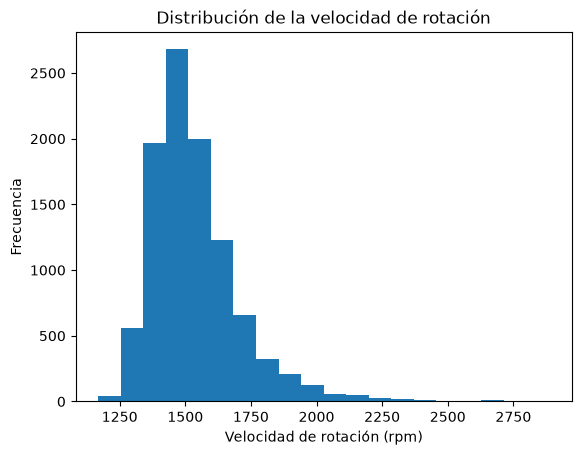

In [299]:
plt.hist(df["Rotational speed [rpm]"], bins=20)
plt.title("Distribución de la velocidad de rotación")
plt.xlabel("Velocidad de rotación (rpm)")
plt.ylabel("Frecuencia")
plt.show()

La distribución de la velocidad de rotación presenta una concentración importante de observaciones alrededor de 1400–1600 rpm y una asimetría positiva, con una cola que se extiende hacia velocidades elevadas. Esto confirma que las velocidades extremas son poco frecuentes dentro del dataset. Sin embargo, estos valores se conservarán porque podrían aportar información relevante para el análisis de fallas.

### Gráfico 2: distribución de temperatura

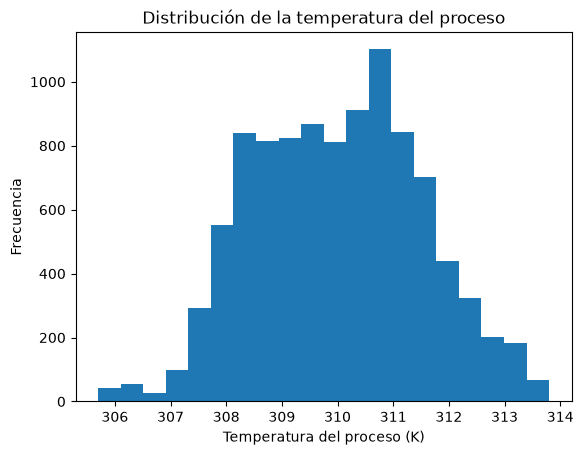

In [300]:
plt.hist(df["Process temperature [K]"], bins=20)
plt.title("Distribución de la temperatura del proceso")
plt.xlabel("Temperatura del proceso (K)")
plt.ylabel("Frecuencia")
plt.show()

In [301]:
df[df["Machine failure"] == 1]

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
50,51,L47230,L,298.9,309.1,2861,4.6,143,1,0,0,1,0,0
69,70,L47249,L,298.9,309.0,1410,65.7,191,1,0,0,1,1,0
77,78,L47257,L,298.8,308.9,1455,41.3,208,1,1,0,0,0,0
160,161,L47340,L,298.4,308.2,1282,60.7,216,1,0,0,0,1,0
161,162,L47341,L,298.3,308.1,1412,52.3,218,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9758,9759,L56938,L,298.6,309.8,2271,16.2,218,1,1,0,0,0,0
9764,9765,L56944,L,298.5,309.5,1294,66.7,12,1,0,0,1,0,0
9822,9823,L57002,L,298.5,309.4,1360,60.9,187,1,0,0,0,1,0
9830,9831,L57010,L,298.3,309.3,1337,56.1,206,1,0,0,0,1,0


In [302]:
temperatura_con_falla = df[df["Machine failure"] == 1]["Process temperature [K]"]

In [303]:
temperatura_sin_falla = df[df["Machine failure"] == 0]["Process temperature [K]"]

### Gráfico 3: temperatura según fallas

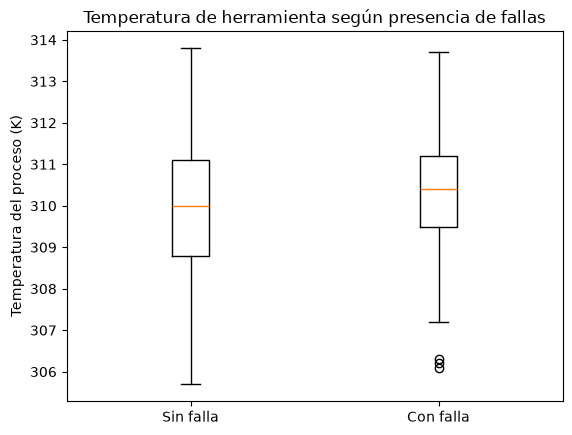

In [332]:
plt.boxplot([temperatura_sin_falla, temperatura_con_falla])
plt.title("Temperatura de herramienta según presencia de fallas")
plt.ylabel("Temperatura del proceso (K)")
plt.xticks([1, 2], ["Sin falla", "Con falla"])
plt.show()

In [305]:
temperatura_con_falla.median()

np.float64(310.4)

In [306]:
temperatura_sin_falla.median()

np.float64(310.0)

El análisis mediante diagramas de caja permitió identificar que la mediana de temperatura del proceso en los registros con falla es de 310,4 K, mientras que en los registros sin falla es de 310,0 K. Aunque se observa una diferencia de 0,4 K, existe un amplio solapamiento entre ambas distribuciones. Esto sugiere que la temperatura del proceso podría aportar información al modelo predictivo, pero debe analizarse conjuntamente con otras variables operacionales.

In [307]:
desgaste_con_falla = df[df["Machine failure"] == 1]["Tool wear [min]"]
print(len(desgaste_con_falla))

339


In [308]:
desgaste_sin_falla = df[df["Machine failure"] == 0]["Tool wear [min]"]
print(len(desgaste_sin_falla))

9661


### Gráfico 4: desgaste según fallas

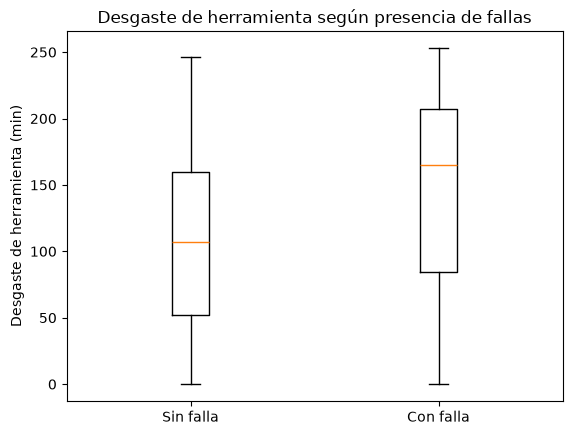

In [309]:
plt.boxplot([desgaste_sin_falla, desgaste_con_falla])
plt.title("Desgaste de herramienta según presencia de fallas")
plt.ylabel("Desgaste de herramienta (min)")
plt.xticks([1, 2], ["Sin falla", "Con falla"])
plt.show()

In [310]:
desgaste_sin_falla.median()

np.float64(107.0)

In [311]:
desgaste_con_falla.median()

np.float64(165.0)

El análisis del desgaste de herramienta muestra una mediana de 165 minutos en los registros con falla y de 107 minutos en aquellos sin falla. La diferencia de 58 minutos sugiere una asociación entre un mayor tiempo acumulado de uso de la herramienta y la presencia de fallas. No obstante, las distribuciones presentan solapamiento, por lo que el desgaste debe evaluarse conjuntamente con otras variables operacionales.

Al comparar las distribuciones de temperatura del proceso y desgaste de herramienta según la presencia de fallas, se observó una separación más pronunciada entre los grupos en la variable de desgaste. Su mediana fue de 165 minutos en los registros con falla, frente a 107 minutos en los registros sin falla. Este resultado sugiere que el desgaste acumulado podría aportar información relevante para la predicción de fallas, aunque su importancia deberá comprobarse durante el modelado.

### Gráfico 5: velocidad y torque

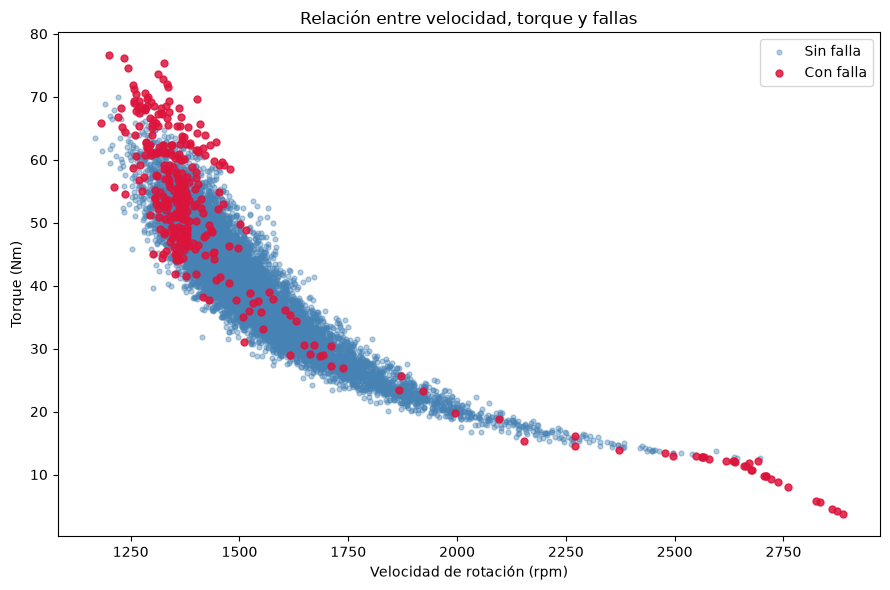

In [312]:
plt.figure(figsize=(9, 6))

for clase, etiqueta, color in [
    (0, "Sin falla", "steelblue"),
    (1, "Con falla", "crimson")
]:
    grupo = df[df["Machine failure"] == clase]
    plt.scatter(
        grupo["Rotational speed [rpm]"],
        grupo["Torque [Nm]"],
        alpha=0.4 if clase == 0 else 0.85,
        s=12 if clase == 0 else 25,
        label=etiqueta,
        color=color
    )

plt.title("Relación entre velocidad, torque y fallas")
plt.xlabel("Velocidad de rotación (rpm)")
plt.ylabel("Torque (Nm)")
plt.legend()
plt.tight_layout()
plt.show()

### Gráfico 6: correlación entre variables

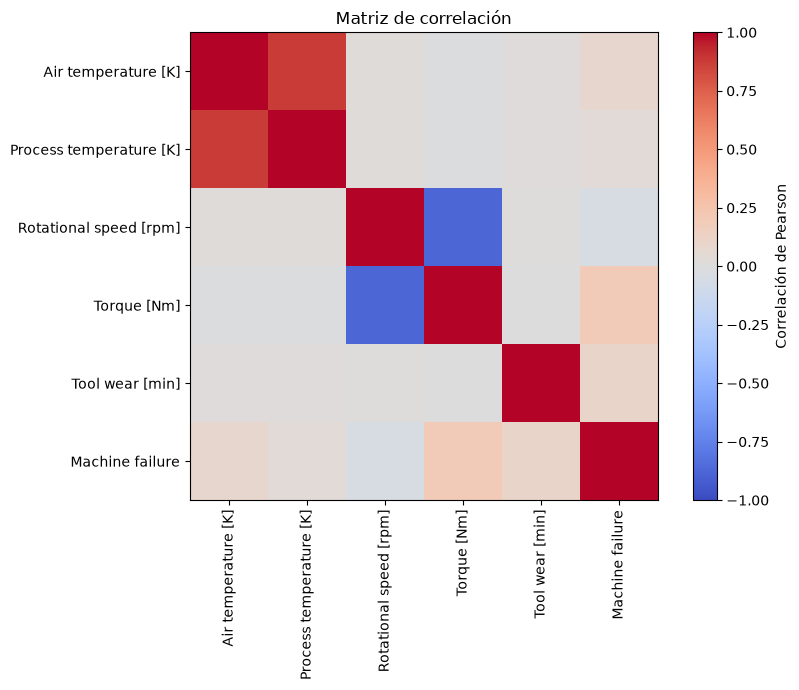

In [313]:
columnas_corr = variables + ["Machine failure"]
correlaciones = df[columnas_corr].corr()

plt.figure(figsize=(9, 7))
plt.imshow(correlaciones, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlación de Pearson")
plt.xticks(range(len(columnas_corr)), columnas_corr, rotation=90)
plt.yticks(range(len(columnas_corr)), columnas_corr)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

3.6 Hallazgos del análisis exploratorio: conclusiones iniciales.

## Hallazgos y conclusiones del Análisis Exploratorio de Datos (EDA)

### 1. Calidad e integridad de los datos

El conjunto de datos AI4I 2020 contiene 10.000 registros de condiciones operacionales de equipos industriales. Durante la exploración se comprobó que no existen valores nulos ni registros duplicados, lo que permite trabajar con una base de datos completa sin necesidad de imputación de valores faltantes.

Se identificaron observaciones extremas en variables operacionales, particularmente en la velocidad de rotación. Estas observaciones se conservaron, dado que podrían representar condiciones relevantes para el estudio de las fallas y no necesariamente errores de registro.

### 2. Desbalance de la variable objetivo

Se identificó un desbalance significativo en la variable *Machine failure*: 9.661 registros (96,61 %) corresponden a equipos sin falla y 339 registros (3,39 %) a equipos con falla.

Este hallazgo es especialmente importante porque un modelo podría alcanzar una exactitud elevada clasificando casi todos los registros como equipos sin falla, pero sin identificar adecuadamente los casos que requieren atención.

Por esta razón, en las etapas posteriores será necesario evaluar el desempeño utilizando métricas como **recall, precision, F1-score y PR-AUC**, además de la exactitud.

### 3. Desgaste de herramienta y ocurrencia de fallas

El análisis del desgaste de herramienta (*Tool wear*) mostró diferencias entre los registros con y sin falla. Se observó una **mediana de desgaste de 165 minutos en los equipos con falla, frente a 107 minutos en los equipos sin falla**.

Este resultado sugiere que el desgaste de herramienta es una variable relevante para identificar condiciones asociadas con una mayor probabilidad de falla.

Sin embargo, no se puede establecer un límite universal de desgaste ni afirmar que un equipo fallará al alcanzar un número específico de minutos. La interpretación debe considerar otras condiciones operacionales.

### 4. Velocidad de rotación y valores extremos

Durante la exploración se identificaron **418 observaciones con velocidades de rotación superiores a 1.895,5 rpm**, utilizando el criterio estadístico aplicado en el análisis. De estas observaciones, 35 correspondieron a registros con falla.

Estos registros se conservaron debido a su posible relevancia operacional. La presencia de fallas entre las velocidades extremas justifica estudiarlas, pero no demuestra que una velocidad elevada provoque necesariamente una falla.

También es importante considerar la posible interacción de la velocidad con el torque y el desgaste de herramienta, en lugar de analizar cada variable de manera aislada.

### 5. Temperatura del proceso y ocurrencia de fallas

El análisis de la temperatura del proceso (*Process temperature*) mostró diferencias pequeñas entre los registros con y sin falla.

La **mediana de temperatura del proceso fue aproximadamente de 310,4 K en los equipos con falla y de 310,0 K en los equipos sin falla**, lo que representa una diferencia de apenas 0,4 K.

Este resultado indica que, al comparar las medianas, la temperatura del proceso no permite distinguir claramente ambos grupos.

No obstante, esto no significa que la temperatura carezca de relevancia. Su contribución a la predicción podría depender de su interacción con otras variables operacionales.

### 6. Implicaciones para el mantenimiento predictivo

Los resultados del EDA muestran que las fallas se presentan en una proporción reducida de los registros y que existen diferencias operacionales que justifican desarrollar un modelo de clasificación.

El desgaste de herramienta y determinadas condiciones de velocidad destacan como señales que merecen atención. Sin embargo, ninguna de las variables examinadas debe interpretarse individualmente como un diagnóstico definitivo.

Por ello, el modelo predictivo deberá combinar distintas características operacionales para estimar el riesgo de falla y apoyar la priorización de inspecciones.

### Conclusión general del EDA

El análisis exploratorio permitió comprobar la calidad de los datos, identificar un desbalance importante de clases y reconocer patrones asociados con la ocurrencia de fallas en equipos industriales.

Los hallazgos respaldan el desarrollo de un modelo de Machine Learning orientado a detectar posibles fallas a partir de condiciones operacionales. Asimismo, evidencian la necesidad de priorizar la detección de fallas reales, sin ignorar el costo de las falsas alarmas.

Dado que AI4I 2020 es un conjunto de datos sintético, los patrones identificados constituyen evidencia útil para desarrollar y evaluar un prototipo académico, pero **no representan límites operacionales validados ni garantizan el desempeño del sistema en una planta industrial real**.

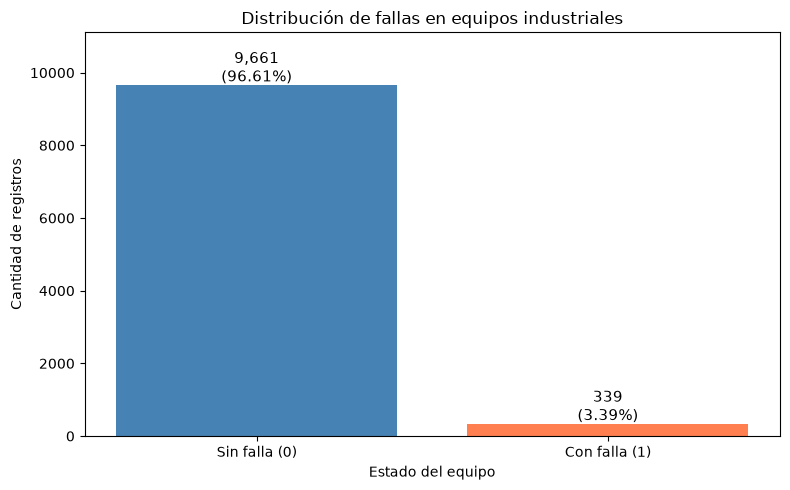

In [333]:
# Distribución de la variable objetivo
conteo_fallas = df["Machine failure"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

barras = plt.bar(
    ["Sin falla (0)", "Con falla (1)"],
    conteo_fallas.values,
    color=["steelblue", "coral"]
)

# Mostrar cantidad y porcentaje encima de cada barra
for barra, cantidad in zip(barras, conteo_fallas.values):
    porcentaje = cantidad / conteo_fallas.sum() * 100
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 100,
        f"{cantidad:,}\n({porcentaje:.2f}%)",
        ha="center",
        fontsize=11
    )

plt.title("Distribución de fallas en equipos industriales")
plt.ylabel("Cantidad de registros")
plt.xlabel("Estado del equipo")
plt.ylim(0, conteo_fallas.max() * 1.15)
plt.tight_layout()
plt.show()


**Hallazgo: Desbalance de la variable objetivo**

La distribución de la variable *Machine failure* evidencia un desbalance significativo entre las dos clases. De los 10.000 registros analizados, 9.661 (96,61 %) corresponden a equipos sin falla y solamente 339 (3,39 %) a equipos con falla.

Este hallazgo representa un desafío para el desarrollo del modelo predictivo, debido a que la clase de mayor interés para el mantenimiento industrial es también la menos frecuente.

Por esta razón, se considera necesario utilizar técnicas que permitan atender el desbalance y evaluar el desempeño mediante métricas como *recall*, *precision*, F1-score y PR-AUC, evitando depender exclusivamente de la exactitud del modelo.

# Resumen estadístico y preparación de datos

In [314]:
resumen = df.groupby("Machine failure")[variables].agg(
    ["mean", "median", "std"]
)

display(resumen)

df_limpio = df.copy()


assert df_limpio[variables].notna().all().all()
assert df_limpio["Machine failure"].isin([0, 1]).all()


df_limpio.to_csv("ai4i2020_limpio.csv", index=False)

with pd.ExcelWriter("EDA_mantenimiento_predictivo.xlsx") as writer:
    df_limpio.to_excel(writer, sheet_name="Datos", index=False)
    resumen.to_excel(writer, sheet_name="Resumen estadistico")
    correlaciones.to_excel(writer, sheet_name="Correlaciones")

print("Archivos del EDA generados correctamente.")

Air temperature [K]                  Process temperature [K]  \
                               mean median       std                    mean   
Machine failure                                                                
0                        299.973999  300.0  1.990748              309.995570   
1                        300.886431  301.6  2.071473              310.290265   

                                 Rotational speed [rpm]                      \
                median       std                   mean  median         std   
Machine failure                                                               
0                310.0  1.486846            1540.260014  1507.0  167.394734   
1                310.4  1.363686            1496.486726  1365.0  384.943547   

                Torque [Nm]                   Tool wear [min]         \
                       mean median        std            mean median   
Machine failure                                                        
0                 39.629655   39.9   9.472080      106.693717  107.0   
1                 50.168142   53.7  16.374498      143.781711  165.0   

                            
                       std  
Machine failure             
0                62.945790  
1                72.759876

Archivos del EDA generados correctamente.


# Modelo de Machine Learning

5.1 Modelo Inicial Baseline

Resultados del modelo:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.72      0.65      0.68        68

    accuracy                           0.98      2000
   macro avg       0.85      0.82      0.84      2000
weighted avg       0.98      0.98      0.98      2000

ROC-AUC: 0.9612828827183048
PR-AUC: 0.7569904382854978


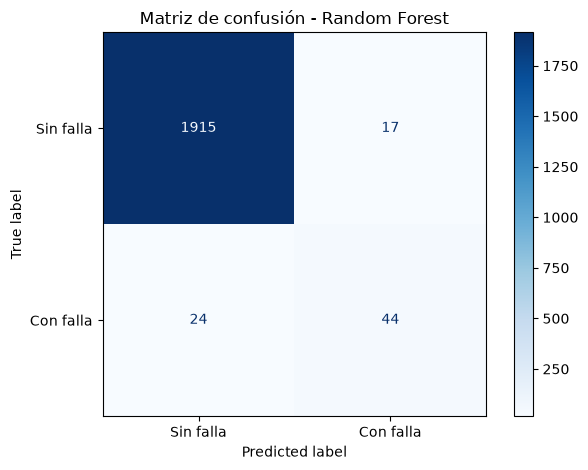

In [315]:
features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = pd.get_dummies(
    df_limpio[features],
    columns=["Type"],
    dtype=int
)

y = df_limpio["Machine failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

modelo = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

print("Resultados del modelo:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Sin falla", "Con falla"],
    cmap="Blues"
)

plt.title("Matriz de confusión - Random Forest")
plt.tight_layout()
plt.show()

## Hallazgos y conclusiones del modelo baseline

### Desempeño general del modelo

Se entrenó un modelo inicial de clasificación Random Forest para predecir la ocurrencia de fallas en equipos electromecánicos a partir de sus condiciones operacionales.

El modelo fue evaluado utilizando un conjunto de prueba de 2.000 registros, de los cuales 68 correspondían a equipos con falla y 1.932 a equipos sin falla.

El modelo baseline obtuvo una exactitud (*accuracy*) del **97,95 %**, lo que indica que clasificó correctamente la mayoría de las observaciones.

Sin embargo, debido al desbalance de clases identificado durante el análisis exploratorio, esta métrica no es suficiente para determinar su efectividad en la detección de fallas.

### Interpretación de la matriz de confusión

La matriz de confusión permitió identificar cuatro resultados:

- **1.915 verdaderos negativos (TN):** equipos sin falla clasificados correctamente.
- **44 verdaderos positivos (TP):** equipos con falla detectados correctamente.
- **17 falsos positivos (FP):** equipos sin falla clasificados incorrectamente como equipos con falla.
- **24 falsos negativos (FN):** equipos que presentaron una falla, pero fueron clasificados como equipos sin falla.

El resultado más relevante desde la perspectiva del mantenimiento predictivo corresponde a los **24 falsos negativos**, debido a que representan fallas que el modelo no logró identificar.

En un entorno industrial, este tipo de error podría ocasionar que un equipo que requiere atención no sea priorizado para inspección, incrementando el riesgo de paradas no planificadas y costos operacionales.

Por otra parte, los 17 falsos positivos podrían generar inspecciones innecesarias, consumo adicional de recursos y posibles interrupciones de las operaciones.

### Interpretación de las métricas de clasificación

El modelo obtuvo una precisión (*precision*) del **72,13 %**, lo que significa que aproximadamente 72 de cada 100 alertas de falla emitidas por el modelo correspondieron a fallas reales.

El *recall* fue del **64,71 %**, indicando que el modelo detectó aproximadamente 65 de cada 100 fallas reales. En consecuencia, no identificó alrededor del 35 % de los casos de falla presentes en el conjunto de prueba.

El F1-score fue aproximadamente **68,22 %**, reflejando el equilibrio alcanzado entre precisión y capacidad de detección.

Aunque el modelo presenta un desempeño general favorable, su capacidad para detectar fallas todavía puede mejorarse.

### Conclusión y oportunidad de mejora

El modelo baseline demostró que es posible utilizar las variables operacionales del dataset para identificar patrones relacionados con fallas en equipos industriales.

No obstante, la matriz de confusión evidencia una limitación importante: **el modelo no detectó 24 de las 68 fallas reales**, a pesar de alcanzar una exactitud superior al 97 %.

Considerando que el objetivo del proyecto es apoyar la detección temprana de posibles fallas, se identificó la necesidad de mejorar el *recall* de la clase positiva, procurando mantener un número razonable de falsas alarmas.

Por esta razón, se decidió continuar con una etapa de optimización del modelo, evaluando diferentes umbrales de clasificación y configuraciones de hiperparámetros para encontrar un equilibrio más adecuado entre la detección de fallas y la generación de alertas innecesarias.

5.2 Optimización del modelo — Validación y ajuste de umbral

In [316]:
X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train_nuevo, X_validacion, y_train_nuevo, y_validacion = train_test_split(
    X_entrenamiento,
    y_entrenamiento,
    test_size=0.25,
    random_state=42,
    stratify=y_entrenamiento
)

In [317]:
umbrales = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

resultados = []

for umbral in umbrales:

    predicciones = (y_prob >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predicciones
    ).ravel()

    resultados.append({
        "Umbral": umbral,
        "Precision": precision_score(
            y_test, predicciones, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predicciones, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predicciones, zero_division=0
        ),
        "Falsos negativos": fn,
        "Falsos positivos": fp
    })

resultados_umbrales = pd.DataFrame(resultados)

display(resultados_umbrales.round(3))

,Umbral,Precision,Recall,F1-score,Falsos negativos,Falsos positivos
0,0.20,0.391,0.868,0.539,9,92
1,0.25,0.457,0.853,0.595,10,69
2,0.30,0.519,0.794,0.628,14,50
3,0.35,0.558,0.779,0.650,15,42
4,0.40,0.607,0.750,0.671,17,33
5,0.45,0.640,0.706,0.671,20,27
6,0.50,0.714,0.662,0.687,23,18


In [318]:
print("Predicciones originales:")
print(confusion_matrix(y_test, y_pred))

print("\nPredicciones con umbral 0.50:")
pred_050 = (y_prob >= 0.50).astype(int)
print(confusion_matrix(y_test, pred_050))

print("\nPredicciones con umbral 0.30:")
pred_030 = (y_prob >= 0.30).astype(int)
print(confusion_matrix(y_test, pred_030))

Predicciones originales:
[[1915   17]
 [  24   44]]

Predicciones con umbral 0.50:
[[1914   18]
 [  23   45]]

Predicciones con umbral 0.30:
[[1882   50]
 [  14   54]]


In [319]:
# Separar entrenamiento y prueba
X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Separar entrenamiento y validación
X_train_nuevo, X_validacion, y_train_nuevo, y_validacion = train_test_split(
    X_entrenamiento,
    y_entrenamiento,
    test_size=0.25,
    random_state=42,
    stratify=y_entrenamiento
)

print("Entrenamiento:", len(X_train_nuevo))
print("Validación:", len(X_validacion))
print("Prueba:", len(X_prueba))

Entrenamiento: 6000
Validación: 2000
Prueba: 2000


In [320]:
modelo_mejorado = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

modelo_mejorado.fit(X_train_nuevo, y_train_nuevo)

print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


In [321]:
prob_validacion = modelo_mejorado.predict_proba(
    X_validacion
)[:, 1]

print("Probabilidades calculadas:", len(prob_validacion))

print("Primeras 10 probabilidades:")
print(prob_validacion[:10])

Probabilidades calculadas: 2000
Primeras 10 probabilidades:
[0.03  0.    0.    0.345 0.    0.045 0.13  0.    0.    0.   ]


In [322]:
umbrales = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

resultados = []

for umbral in umbrales:

    predicciones = (prob_validacion >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_validacion, predicciones, labels=[0, 1]
    ).ravel()

    resultados.append({
        "Umbral": umbral,
        "Precision": precision_score(
            y_validacion, predicciones, zero_division=0
        ),
        "Recall": recall_score(
            y_validacion, predicciones, zero_division=0
        ),
        "F1-score": f1_score(
            y_validacion, predicciones, zero_division=0
        ),
        "Falsos negativos": fn,
        "Falsos positivos": fp
    })

tabla_validacion = pd.DataFrame(resultados)

display(tabla_validacion.round(3))

,Umbral,Precision,Recall,F1-score,Falsos negativos,Falsos positivos
0,0.20,0.329,0.824,0.471,12,114
1,0.25,0.370,0.794,0.505,14,92
2,0.30,0.419,0.765,0.542,16,72
3,0.35,0.452,0.691,0.547,21,57
4,0.40,0.506,0.662,0.573,23,44
5,0.45,0.538,0.632,0.581,25,37
6,0.50,0.609,0.574,0.591,29,25


## Hallazgos y conclusiones del ajuste del umbral de clasificación

### Objetivo del ajuste

Después de evaluar el modelo baseline, se identificó la necesidad de mejorar su capacidad para detectar fallas reales en los equipos industriales.

Inicialmente, el modelo Random Forest utilizaba un umbral de clasificación de **0,50**, lo que significa que clasificaba un registro como falla cuando la probabilidad estimada era igual o superior al 50 %.

Sin embargo, la matriz de confusión mostró que este criterio dejaba sin detectar una proporción importante de las fallas reales.

Por esta razón, se decidió experimentar con diferentes umbrales de clasificación, con el objetivo de aumentar el *recall* y reducir los falsos negativos, considerando que una falla no detectada puede representar un riesgo operativo importante.

### Proceso de evaluación

Se analizaron distintos umbrales entre 0,20 y 0,50 utilizando el conjunto de validación, comparando las métricas de *precision*, *recall*, F1-score y la cantidad de falsos positivos y falsos negativos.

Los resultados mostraron que reducir el umbral permitía identificar una mayor proporción de fallas reales. No obstante, también incrementaba la cantidad de falsas alarmas.

Por ejemplo, con el modelo evaluado antes de la optimización de hiperparámetros:

- **Umbral 0,50:** recall de 57,4 %, con 29 falsos negativos y 25 falsos positivos.
- **Umbral 0,30:** recall de 76,5 %, con 16 falsos negativos y 72 falsos positivos.
- **Umbral 0,20:** recall de 82,4 %, con 12 falsos negativos y 114 falsos positivos.

Estos resultados evidenciaron la relación entre la sensibilidad del modelo para detectar fallas y la cantidad de alertas generadas.

### Justificación de la selección del umbral 0,30

En esta primera etapa se seleccionó un **umbral de 0,30** como alternativa al valor predeterminado de 0,50.

Esta decisión buscó mejorar la detección de fallas sin adoptar el umbral más bajo, que generaba una cantidad considerablemente mayor de falsas alarmas.

La selección respondió al objetivo del proyecto: priorizar la identificación de equipos potencialmente vulnerables, manteniendo un equilibrio razonable entre las fallas detectadas y las inspecciones innecesarias.

### Conclusión del proceso

El ajuste del umbral permitió comprobar que el desempeño de un modelo de clasificación no depende únicamente del algoritmo utilizado, sino también del criterio empleado para transformar sus probabilidades en decisiones.

Se concluyó que el umbral predeterminado de 0,50 no necesariamente representa la mejor alternativa para un problema de mantenimiento predictivo, especialmente cuando las fallas son poco frecuentes y su omisión puede tener consecuencias operacionales importantes.

La evaluación permitió seleccionar provisionalmente el umbral de **0,30**, priorizando el *recall* frente a la precisión. Posteriormente, se decidió continuar con la optimización de los hiperparámetros del Random Forest y realizar una nueva evaluación del umbral, con el propósito de mejorar el equilibrio entre detección de fallas y falsas alarmas.

5.3 Entrenamiento nuevo modelo con umbral 0.30

Evaluación del modelo con umbral 0.30
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1932
           1       0.47      0.81      0.59        68

    accuracy                           0.96      2000
   macro avg       0.73      0.89      0.79      2000
weighted avg       0.98      0.96      0.97      2000

ROC-AUC: 0.9572372427231763
PR-AUC: 0.7019278113064163


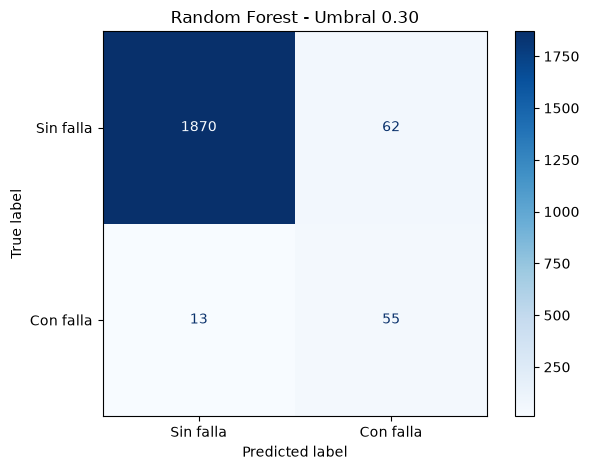

In [323]:
# Probabilidades en el conjunto de prueba
prob_prueba = modelo_mejorado.predict_proba(
    X_prueba
)[:, 1]

# Umbral seleccionado en validación
umbral_optimo = 0.30

pred_prueba = (
    prob_prueba >= umbral_optimo
).astype(int)

print("Evaluación del modelo con umbral 0.30")

print(classification_report(
    y_prueba,
    pred_prueba,
    zero_division=0
))

print("ROC-AUC:", roc_auc_score(
    y_prueba, prob_prueba
))

print("PR-AUC:", average_precision_score(
    y_prueba, prob_prueba
))

ConfusionMatrixDisplay.from_predictions(
    y_prueba,
    pred_prueba,
    display_labels=["Sin falla", "Con falla"],
    cmap="Blues"
)

plt.title("Random Forest - Umbral 0.30")
plt.tight_layout()
plt.show()

5.4 Modificar hyperparametros del Random Forest

In [324]:
# Modelo base para optimización
rf_base = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Hiperparámetros que vamos a explorar
parametros = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"],
    "class_weight": ["balanced", "balanced_subsample"]
}

# Validación cruzada estratificada
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Búsqueda aleatoria
busqueda_rf = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=parametros,
    n_iter=15,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Entrenar únicamente con el conjunto de entrenamiento
busqueda_rf.fit(X_train_nuevo, y_train_nuevo)

print("\nMejores hiperparámetros:")
print(busqueda_rf.best_params_)

print("\nMejor PR-AUC promedio en validación cruzada:")
print(round(busqueda_rf.best_score_, 4))

Fitting 3 folds for each of 15 candidates, totalling 45 fits

Mejores hiperparámetros:
{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 20, 'class_weight': 'balanced'}

Mejor PR-AUC promedio en validación cruzada:
0.7001


In [325]:
modelo_optimizado = busqueda_rf.best_estimator_

# Probabilidades del modelo optimizado
prob_optimizadas = modelo_optimizado.predict_proba(
    X_validacion
)[:, 1]

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

print("COMPARACIÓN EN VALIDACIÓN")

print("\nModelo anterior:")
print("PR-AUC:", round(
    average_precision_score(y_validacion, prob_validacion), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_validacion, prob_validacion), 4
))

print("\nModelo optimizado:")
print("PR-AUC:", round(
    average_precision_score(y_validacion, prob_optimizadas), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_validacion, prob_optimizadas), 4
))

COMPARACIÓN EN VALIDACIÓN

Modelo anterior:
PR-AUC: 0.6481
ROC-AUC: 0.9624

Modelo optimizado:
PR-AUC: 0.6879
ROC-AUC: 0.966


In [326]:
umbrales = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

resultados_optimizados = []

for umbral in umbrales:

    pred = (prob_optimizadas >= umbral).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_validacion,
        pred,
        labels=[0, 1]
    ).ravel()

    resultados_optimizados.append({
        "Umbral": umbral,
        "Precision": precision_score(
            y_validacion, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_validacion, pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_validacion, pred, zero_division=0
        ),
        "Falsos negativos": fn,
        "Falsos positivos": fp
    })

tabla_optimizada = pd.DataFrame(resultados_optimizados)

display(tabla_optimizada.round(3))

,Umbral,Precision,Recall,F1-score,Falsos negativos,Falsos positivos
0,0.20,0.274,0.882,0.418,8,159
1,0.25,0.302,0.853,0.446,10,134
2,0.30,0.341,0.838,0.485,11,110
3,0.35,0.377,0.809,0.514,13,91
4,0.40,0.421,0.779,0.546,15,73
5,0.45,0.472,0.750,0.580,17,57
6,0.50,0.500,0.721,0.590,19,49


MODELO RANDOM FOREST OPTIMIZADO
Umbral: 0.4

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1932
           1       0.47      0.84      0.61        68

    accuracy                           0.96      2000
   macro avg       0.73      0.90      0.79      2000
weighted avg       0.98      0.96      0.97      2000

ROC-AUC: 0.9599
PR-AUC: 0.7264


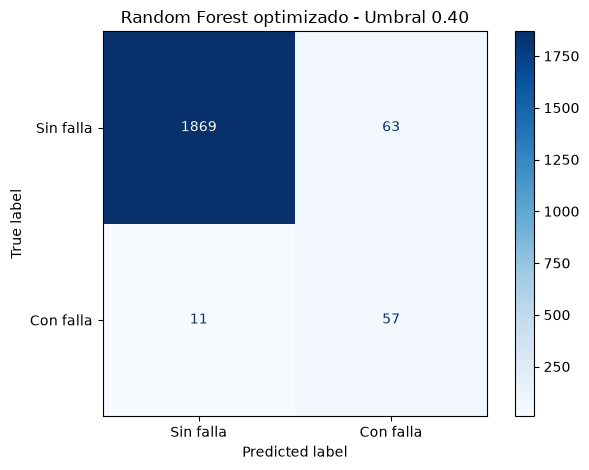

In [327]:
# Probabilidades del modelo optimizado
prob_final = modelo_optimizado.predict_proba(
    X_prueba
)[:, 1]

# Umbral seleccionado en validación
umbral_final = 0.40

pred_final = (prob_final >= umbral_final).astype(int)

print("MODELO RANDOM FOREST OPTIMIZADO")
print("Umbral:", umbral_final)

print("\nReporte de clasificación:")
print(classification_report(
    y_prueba,
    pred_final,
    zero_division=0
))

print("ROC-AUC:", round(
    roc_auc_score(y_prueba, prob_final), 4
))

print("PR-AUC:", round(
    average_precision_score(y_prueba, prob_final), 4
))

ConfusionMatrixDisplay.from_predictions(
    y_prueba,
    pred_final,
    display_labels=["Sin falla", "Con falla"],
    cmap="Blues"
)

plt.title("Random Forest optimizado - Umbral 0.40")
plt.tight_layout()
plt.show()

## Hallazgos y conclusiones de la optimización de hiperparámetros del Random Forest

### Objetivo de la optimización

Después de evaluar el modelo baseline y experimentar con diferentes umbrales de clasificación, se identificó la oportunidad de mejorar el desempeño del Random Forest mediante el ajuste de sus hiperparámetros.

Aunque la modificación del umbral permitió incrementar la detección de fallas, este procedimiento no modificaba el aprendizaje interno del modelo, sino únicamente el criterio utilizado para clasificar las probabilidades estimadas.

Por esta razón, se decidió optimizar los hiperparámetros del algoritmo, buscando una mejor capacidad de discriminación entre equipos con y sin falla.

### Metodología utilizada

Se implementó `RandomizedSearchCV` para explorar diferentes combinaciones de hiperparámetros del Random Forest, utilizando validación cruzada estratificada de tres particiones (*StratifiedKFold*).

La búsqueda evaluó 15 combinaciones de hiperparámetros y utilizó como criterio de optimización la métrica **average precision**, apropiada para problemas de clasificación con clases desbalanceadas.

Se exploraron parámetros relacionados con el número y la profundidad de los árboles, las condiciones mínimas para dividir nodos, la cantidad mínima de observaciones por hoja, las variables consideradas en cada división y los pesos asignados a las clases.

### Hiperparámetros seleccionados

La búsqueda identificó la siguiente configuración:

| Hiperparámetro | Valor seleccionado |
|---|---|
| `n_estimators` | 200 |
| `max_depth` | 20 |
| `min_samples_split` | 2 |
| `min_samples_leaf` | 2 |
| `max_features` | `log2` |
| `class_weight` | `balanced` |

Esta configuración limita la profundidad máxima de los árboles, exige al menos dos observaciones por hoja y mantiene una ponderación de clases para atender el desbalance del dataset.

El mejor valor promedio de *average precision* obtenido durante la validación cruzada fue de **0,7001**.

### Comparación del desempeño antes y después de la optimización

La evaluación sobre el conjunto de validación mostró los siguientes resultados:

| Métrica | Modelo anterior | Modelo optimizado |
|---|---:|---:|
| PR-AUC | 0,6481 | 0,6879 |
| ROC-AUC | 0,9624 | 0,9660 |

La mejora más relevante se observó en el área bajo la curva precisión-recall (PR-AUC), que pasó de 0,6481 a 0,6879.

Este resultado sugiere que la configuración optimizada logró una mejor relación global entre precisión y capacidad de detección de fallas a través de distintos umbrales de clasificación.

Por otra parte, el ROC-AUC también presentó una mejora, aunque de menor magnitud.

### Interpretación de los resultados

Los resultados muestran que la optimización de hiperparámetros permitió mejorar el desempeño del Random Forest sobre los datos de validación, especialmente en una métrica relevante para la clase minoritaria.

Sin embargo, una mejora en PR-AUC no garantiza automáticamente que todas las métricas mejoren al utilizar un umbral específico.

Por ello, después de seleccionar la configuración optimizada, fue necesario realizar una nueva evaluación de los umbrales de clasificación para determinar cuál ofrecía un equilibrio más adecuado entre fallas detectadas y falsas alarmas.

### Conclusión del proceso

La optimización mediante `RandomizedSearchCV` permitió identificar una configuración del Random Forest con mejor desempeño en validación que la configuración utilizada anteriormente.

Este proceso demostró la importancia de complementar el ajuste del umbral de clasificación con la optimización de los parámetros que controlan el aprendizaje del algoritmo.

Asimismo, permitió establecer una metodología de mejora basada en resultados cuantitativos y validación cruzada, en lugar de seleccionar arbitrariamente una configuración.

Aunque los resultados fueron favorables, la mejora observada debe interpretarse dentro del contexto de un dataset sintético y no

# Importancia de las variables

,Variable,Importancia
3,Torque [Nm],0.324709
2,Rotational speed [rpm],0.314261
4,Tool wear [min],0.196872
0,Air temperature [K],0.091523
1,Process temperature [K],0.058124
6,Type_L,0.006097
7,Type_M,0.005164
5,Type_H,0.003251


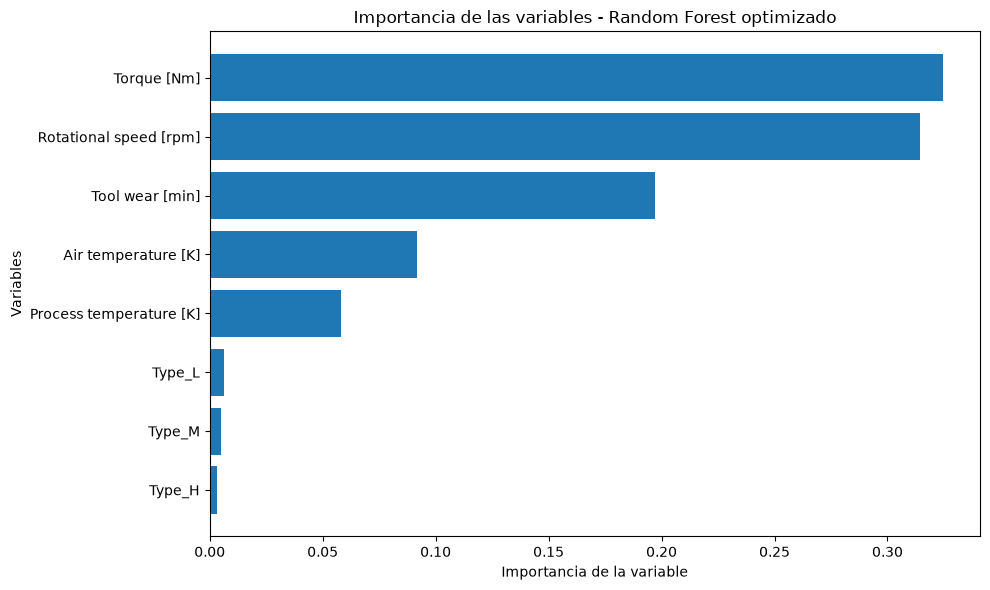

In [328]:
importancia_variables = pd.DataFrame({
    "Variable": X.columns,
    "Importancia": modelo_optimizado.feature_importances_
})

importancia_variables = importancia_variables.sort_values(
    by="Importancia",
    ascending=False
)

display(importancia_variables)

plt.figure(figsize=(10, 6))

plt.barh(
    importancia_variables["Variable"],
    importancia_variables["Importancia"]
)

plt.xlabel("Importancia de la variable")
plt.ylabel("Variables")
plt.title("Importancia de las variables - Random Forest optimizado")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Conclusión del análisis de importancia de variables

El análisis de importancia de características del modelo Random Forest optimizado identificó el torque, la velocidad de rotación y el desgaste de herramienta como las variables de mayor relevancia para la clasificación de fallas en equipos electromecánicos.

Estas tres variables concentraron aproximadamente el 83 % de la importancia total del modelo, lo que sugiere que las condiciones mecánicas y el desgaste desempeñan un papel destacado en sus predicciones.

Las temperaturas del aire y del proceso presentaron una contribución menor, mientras que la categoría del producto tuvo una importancia relativamente baja.

Estos resultados son coherentes con varios hallazgos del análisis exploratorio y permiten identificar variables prioritarias para el monitoreo operativo. Sin embargo, las importancias calculadas por Random Forest no establecen relaciones causales y deben interpretarse considerando las limitaciones del conjunto de datos y del modelo.

7. Guardar el modelo entrenado

In [329]:
import joblib

joblib.dump(
    {
        "modelo": modelo_optimizado,
        "columnas": X.columns.tolist(),
        "features_originales": features,
        "umbral": 0.40,
        "hiperparametros": busqueda_rf.best_params_
    },
    "modelo_rf_optimizado.joblib"
)

print("Modelo optimizado guardado correctamente.")

Modelo optimizado guardado correctamente.


# Conclusiones finales del proyecto

## Predicción de fallas en equipos electromecánicos mediante Inteligencia Artificial para mantenimiento predictivo

### 1. Cumplimiento del objetivo del proyecto

El proyecto permitió desarrollar y evaluar un prototipo de Machine Learning orientado a identificar posibles fallas en equipos electromecánicos a partir de variables operacionales, utilizando el conjunto de datos AI4I 2020 Predictive Maintenance.

Mediante un modelo de clasificación Random Forest, se demostró que es posible identificar patrones asociados con la ocurrencia de fallas y generar estimaciones que podrían apoyar la toma de decisiones en mantenimiento industrial.

El objetivo no fue predecir el momento exacto de una falla, sino clasificar las condiciones operacionales de los equipos según la presencia o ausencia de una posible falla.

### 2. Principales hallazgos del análisis exploratorio

El análisis exploratorio permitió identificar características importantes del conjunto de datos:

- Se analizaron 10.000 registros sin valores nulos ni duplicados.
- Se identificó un desbalance significativo de clases: el 96,61 % de los registros correspondía a equipos sin falla y únicamente el 3,39 % a equipos con falla.
- El desgaste de herramienta presentó valores centrales superiores en los registros con falla.
- Se identificaron velocidades de rotación extremas que se conservaron por su posible relevancia operacional.
- La temperatura del proceso mostró diferencias pequeñas entre los grupos al comparar sus valores centrales.

Estos hallazgos evidenciaron la importancia de evaluar múltiples variables operacionales y considerar sus posibles interacciones, evitando establecer diagnósticos a partir de una sola característica.

### 3. Desarrollo y evaluación del modelo baseline

El modelo inicial Random Forest obtuvo una exactitud del 97,95 %, una precisión del 72,13 % y un recall del 64,71 % para la clase de falla.

Aunque la exactitud fue elevada, la matriz de confusión mostró que el modelo no identificó 24 de las 68 fallas reales presentes en el conjunto de prueba.

Este resultado permitió comprender que, en problemas con clases desbalanceadas, una exactitud elevada no garantiza una detección adecuada de los eventos menos frecuentes.

Desde la perspectiva del mantenimiento predictivo, se consideró especialmente importante reducir los falsos negativos, debido a las posibles consecuencias operacionales de no detectar una condición de falla.

### 4. Mejora del modelo mediante ajuste de umbral e hiperparámetros

Para mejorar la capacidad de detección, se realizaron dos procesos complementarios.

Primero, se evaluaron diferentes umbrales de clasificación, comprobando que reducir el umbral predeterminado de 0,50 incrementaba el recall, aunque también generaba más falsas alarmas.

Posteriormente, se optimizaron los hiperparámetros del Random Forest mediante RandomizedSearchCV y validación cruzada estratificada, utilizando average precision como criterio de selección.

La optimización permitió mejorar el PR-AUC de validación de 0,6481 a 0,6879.

Después de una nueva evaluación de los umbrales, se seleccionó un valor final de **0,40** para el modelo optimizado

Final del Proyecto.